# 🍽️ Zomato Bangalore Restaurants — Data Cleaning & AI Preparation Pipeline
### **Project Goal:** Clean, deduplicate, and prepare the dataset for training Machine Learning / AI models.
---
### 📌 Executive Summary for the AI Team:
* **Raw Data:** 51,717 rows × 17 columns (574 MB on disk, ~900 MB in RAM).
* **Key Challenge Identified:** 39,218 rows were duplicates of the same restaurants scraped across multiple delivery zones and types. This posed a severe **Data Leakage** risk for train/test splits.
* **Cleaning Highlights:**
  1. **Deduplication:** Reduced to **12,499 unique restaurant locations**, preserving the most updated record (highest votes).
  2. **Target (`rate`):** Cleaned ratings into float (`1.8` - `4.9`), created `is_new_restaurant` binary feature for `'NEW'` restaurants.
  3. **Numeric Features:** Cleaned `approx_cost(for two people)` and imputed missing values using median by restaurant type.
  4. **Categorical & High-Cardinality Handling:** Converted `online_order` & `book_table` to binary (0/1), extracted `primary_cuisine`, `primary_rest_type`, and engineered `num_cuisines`. Grouped rare categories (< 30 occurrences) into `'Other'`.
  5. **Memory Optimization:** Dropped raw bloated text columns (`reviews_list`, `menu_item`, `url`, `phone`), reducing dataset size from **574 MB to under 1 MB!**
  6. **Exports:** Created `zomato_ml_ready.csv` (labeled data for training), `zomato_unrated_inference.csv` (for prediction), and `zomato_cleaned.csv` (master cleaned dataset).

## 1. Importing Libraries & Configuring Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading Raw Data & Initial Inspection

In [2]:
df = pd.read_csv('zomato.csv')
print(f"Raw Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df.head())

Raw Dataset Shape: 51,717 rows, 17 columns


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [3]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes,
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values(by='Missing_Count', ascending=False)

print("=== Missing Values Summary in Raw Data ===")
display(missing_summary)

=== Missing Values Summary in Raw Data ===


,Data_Type,Missing_Count,Missing_Percentage (%)
dish_liked,str,28078,54.29
rate,str,7775,15.03
phone,str,1208,2.34
approx_cost(for two people),str,346,0.67
rest_type,str,227,0.44
cuisines,str,45,0.09
location,str,21,0.04
url,str,0,0.00
address,str,0,0.00
votes,int64,0,0.00


## 3. Resolving Hidden Duplicates & Preventing Data Leakage
> ⚠️ **Critical Discovery:** 
> Calling `df.duplicated().sum()` on all columns returned `0` because the `url` column contains unique query parameters.
> However, checking `[name, address]` reveals that **39,218 rows (75.8%)** are duplicate listings of the same restaurant across different delivery zones (`listed_in(city)`) and service types (`listed_in(type)`).
> 
> Training an ML model without deduplication would cause severe **Data Leakage**, as the same restaurant with identical features would appear in both training and test sets.

In [4]:
print("Exact full-row duplicates (including URL):", df.duplicated().sum())

duplicate_restaurants = df.duplicated(subset=['name', 'address']).sum()
print(f"Duplicate restaurant listings [name, address]: {duplicate_restaurants:,} rows ({duplicate_restaurants / len(df) * 100:.1f}%)")

# Sort by votes descending so that dropping duplicates retains the record with the most votes / latest updates
df_sorted = df.sort_values(by='votes', ascending=False)
zomato = df_sorted.drop_duplicates(subset=['name', 'address']).reset_index(drop=True)

print(f"\nCleaned Unique Restaurants Shape: {zomato.shape[0]:,} rows, {zomato.shape[1]} columns")

Exact full-row duplicates (including URL): 0
Duplicate restaurant listings [name, address]: 39,218 rows (75.8%)

Cleaned Unique Restaurants Shape: 12,499 rows, 17 columns


## 4. Target Variable Preprocessing (`rate`) & 'NEW' Feature Flag
* Restaurants with `rate == 'NEW'` (590 restaurants) are newly opened without ratings yet. We create a dedicated feature: `is_new_restaurant`.
* Format `rate` by removing `/5` and whitespace, then parse to numeric `float64`.
* Rows with missing `rate` cannot be used to train a supervised model targeting rating, but are preserved for inference.

In [5]:
# 1. Flag new restaurants
zomato['is_new_restaurant'] = (zomato['rate'] == 'NEW').astype(int)

# 2. Clean rate strings (e.g. '4.1/5' -> '4.1')
clean_rate = (
    zomato['rate']
    .astype(str)
    .str.strip()
    .str.replace(' ', '', regex=False)
    .str.replace('/5', '', regex=False)
)
zomato['rate'] = pd.to_numeric(clean_rate, errors='coerce')

print("=== Rating Statistics after Cleaning ===")
print(zomato['rate'].describe())
print(f"\nRated restaurants (Target available for ML): {zomato['rate'].notnull().sum():,}")
print(f"Unrated / New restaurants (For inference): {zomato['rate'].isnull().sum():,}")

=== Rating Statistics after Cleaning ===
count   9487.00
mean       3.63
std        0.43
min        1.80
25%        3.30
50%        3.70
75%        3.90
max        4.90
Name: rate, dtype: float64

Rated restaurants (Target available for ML): 9,487
Unrated / New restaurants (For inference): 3,012


## 5. Cleaning Numeric Features & Smart Imputation (`cost`)
* Remove commas (e.g., `'1,200'` -> `1200`) and convert to `float64`.
* Smart Imputation: Impute the 87 missing values using the **median cost of the respective restaurant type (`rest_type`)**, falling back to the overall median cost.

In [6]:
cost_col = 'approx_cost(for two people)'

# Clean commas and parse
zomato[cost_col] = (
    zomato[cost_col]
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)
zomato['cost'] = pd.to_numeric(zomato[cost_col], errors='coerce')

print(f"Missing cost before imputation: {zomato['cost'].isnull().sum()}")

# Smart Group Median Imputation
median_by_type = zomato.groupby('rest_type')['cost'].transform('median')
zomato['cost'] = zomato['cost'].fillna(median_by_type).fillna(zomato['cost'].median())

print(f"Missing cost after imputation: {zomato['cost'].isnull().sum()}")
print("\n=== Cost Distribution ===")
print(zomato['cost'].describe())

Missing cost before imputation: 87
Missing cost after imputation: 0

=== Cost Distribution ===
count   12499.00
mean      487.96
std       390.68
min        40.00
25%       250.00
50%       400.00
75%       600.00
max      6000.00
Name: cost, dtype: float64


## 6. Categorical Cleaning & Feature Engineering
1. **Binary Encoding:** Convert `online_order` and `book_table` from `'Yes'/'No'` to `1/0`.
2. **Missing Location:** Impute missing locations from `listed_in(city)`.
3. **Cuisine Engineering:** 
   - Extract `primary_cuisine` (first cuisine listed).
   - Engineer `num_cuisines` (count of cuisines offered by the restaurant).
4. **Restaurant Type:** Extract `primary_rest_type`.
5. **High-Cardinality Handling:** Group rare locations, cuisines, and restaurant types (< 30 occurrences) into `'Other'` to prevent dimensionality explosion during One-Hot / Target encoding.

In [7]:
# 1. Binary flags
zomato['online_order_binary'] = (zomato['online_order'] == 'Yes').astype(int)
zomato['book_table_binary'] = (zomato['book_table'] == 'Yes').astype(int)

# 2. Location
zomato['location'] = zomato['location'].fillna(zomato['listed_in(city)'])
loc_counts = zomato['location'].value_counts()
zomato['location_clean'] = zomato['location'].apply(lambda x: x if loc_counts.get(x, 0) >= 30 else 'Other')

# 3. Rest Type
zomato['rest_type'] = zomato['rest_type'].fillna('Quick Bites')
zomato['primary_rest_type'] = zomato['rest_type'].apply(lambda x: str(x).split(',')[0].strip())
rest_counts = zomato['primary_rest_type'].value_counts()
zomato['primary_rest_type'] = zomato['primary_rest_type'].apply(lambda x: x if rest_counts.get(x, 0) >= 30 else 'Other')

# 4. Cuisines
zomato['cuisines'] = zomato['cuisines'].fillna('North Indian')
zomato['num_cuisines'] = zomato['cuisines'].apply(lambda x: len(str(x).split(',')))
zomato['primary_cuisine'] = zomato['cuisines'].apply(lambda x: str(x).split(',')[0].strip())
cuis_counts = zomato['primary_cuisine'].value_counts()
zomato['primary_cuisine'] = zomato['primary_cuisine'].apply(lambda x: x if cuis_counts.get(x, 0) >= 30 else 'Other')

# 5. Service Type
zomato['type'] = zomato['listed_in(type)'].fillna('Delivery')

print("=== Feature Engineering Summary ===")
print(f"Locations count (reduced to top): {zomato['location_clean'].nunique()}")
print(f"Primary Restaurant Types count: {zomato['primary_rest_type'].nunique()}")
print(f"Primary Cuisines count: {zomato['primary_cuisine'].nunique()}")
print(f"Service Types: {zomato['type'].nunique()}")

=== Feature Engineering Summary ===
Locations count (reduced to top): 67
Primary Restaurant Types count: 18
Primary Cuisines count: 36
Service Types: 7


## 7. Memory Optimization & Exporting Clean Datasets
We drop uninformative and high-memory bloat columns:
* `reviews_list`: Consumed over **876 MB of RAM** as unparsed text strings.
* `menu_item`: 77% empty list strings (`'[]'`).
* `url` & `phone`: High-cardinality identifiers that cause overfitting.
* `address`: Redundant street address text with high cardinality.
* `dish_liked`: Over 54% missing values.

### Datasets Exported:
1. `zomato_ml_ready.csv`: Cleaned tabular dataset with labeled targets for AI model training.
2. `zomato_unrated_inference.csv`: Unrated/new restaurants ready for inference.
3. `zomato_cleaned.csv`: Master cleaned dataset for general analytics.

In [8]:
feature_cols = [
    'name', 'online_order_binary', 'book_table_binary', 'rate', 'votes',
    'cost', 'location_clean', 'primary_rest_type', 'primary_cuisine',
    'num_cuisines', 'type'
]

# 1. ML Ready Dataset (Supervised Training)
ml_ready = zomato[zomato['rate'].notnull()][feature_cols].copy()
ml_ready.to_csv('zomato_ml_ready.csv', index=False)

# 2. Unrated Inference Dataset
inference_cols = [c for c in feature_cols if c != 'rate'] + ['is_new_restaurant']
inference_df = zomato[zomato['rate'].isnull()][inference_cols].copy()
inference_df.to_csv('zomato_unrated_inference.csv', index=False)

# 3. Master Cleaned Dataset
master_cols = [
    'name', 'online_order', 'book_table', 'rate', 'is_new_restaurant', 'votes',
    'cost', 'location', 'location_clean', 'rest_type', 'primary_rest_type',
    'cuisines', 'primary_cuisine', 'num_cuisines', 'type', 'address'
]
zomato[master_cols].to_csv('zomato_cleaned.csv', index=False)

print("Files Exported Successfully:")
print(f"1. zomato_ml_ready.csv:           {ml_ready.shape[0]:,} rows x {ml_ready.shape[1]} columns")
print(f"2. zomato_unrated_inference.csv:  {inference_df.shape[0]:,} rows x {inference_df.shape[1]} columns")
print(f"3. zomato_cleaned.csv:            {zomato.shape[0]:,} rows x {len(master_cols)} columns")

Files Exported Successfully:
1. zomato_ml_ready.csv:           9,487 rows x 11 columns
2. zomato_unrated_inference.csv:  3,012 rows x 11 columns
3. zomato_cleaned.csv:            12,499 rows x 16 columns


## 8. Quality Validation & Feature Correlation with Target

Missing Values in ML-Ready Dataset:
name                   0
online_order_binary    0
book_table_binary      0
rate                   0
votes                  0
cost                   0
location_clean         0
primary_rest_type      0
primary_cuisine        0
num_cuisines           0
type                   0
dtype: int64


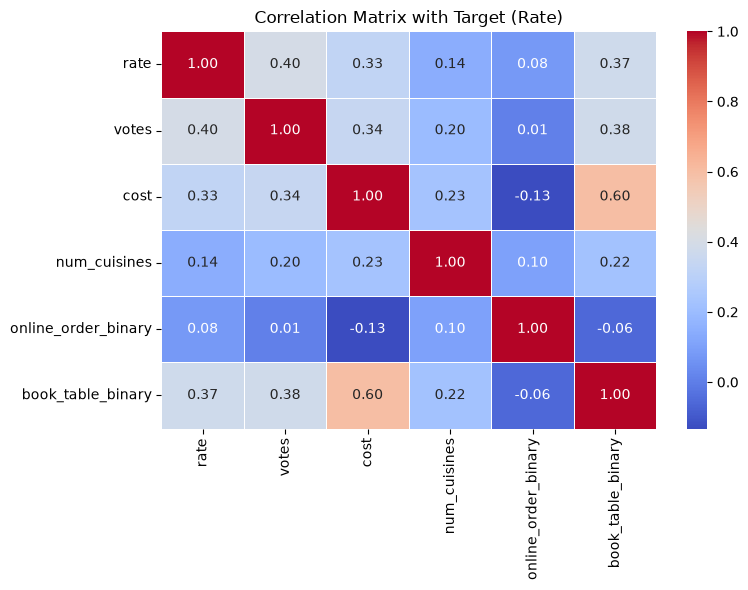


Correlation with Restaurant Rating (rate):
rate                  1.00
votes                 0.40
book_table_binary     0.37
cost                  0.33
num_cuisines          0.14
online_order_binary   0.08
Name: rate, dtype: float64


In [9]:
print("Missing Values in ML-Ready Dataset:")
print(ml_ready.isnull().sum())

numeric_cols = ['rate', 'votes', 'cost', 'num_cuisines', 'online_order_binary', 'book_table_binary']
corr = ml_ready[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix with Target (Rate)')
plt.tight_layout()
plt.show()

print("\nCorrelation with Restaurant Rating (rate):")
print(corr['rate'].sort_values(ascending=False))

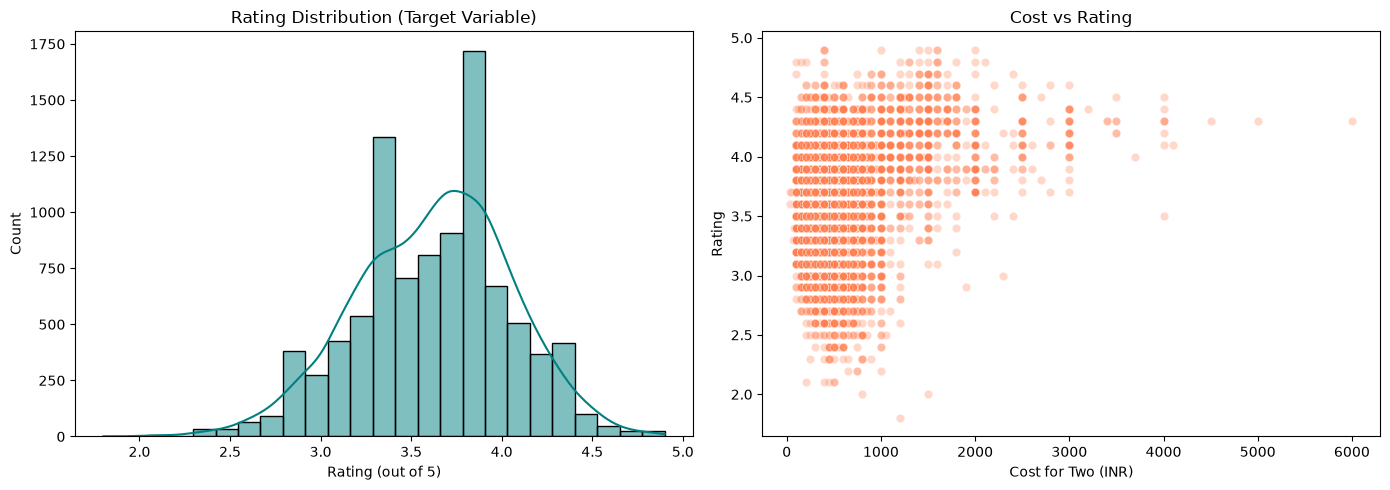

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Rating Distribution
sns.histplot(ml_ready['rate'], kde=True, bins=25, ax=axes[0], color='teal')
axes[0].set_title('Rating Distribution (Target Variable)')
axes[0].set_xlabel('Rating (out of 5)')

# Cost vs Rating
sns.scatterplot(x='cost', y='rate', data=ml_ready, alpha=0.3, ax=axes[1], color='coral')
axes[1].set_title('Cost vs Rating')
axes[1].set_xlabel('Cost for Two (INR)')
axes[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()

## 9. 📋 Handover Guide & Next Steps for the AI / ML Team
---
### 1. Target Variable Definition:
* **Task Type:** Regression (predicting continuous `rate` between 1.8 and 4.9) OR Classification (binning into categories, e.g. `< 3.7` Low, `3.7 - 4.2` Medium, `> 4.2` High-rated).
* **Missing Targets:** Zero missing values in `zomato_ml_ready.csv`.

### 2. Feature Recommendations:
* **Numeric Features:** `votes`, `cost`, `num_cuisines`. Notice strong positive correlation between `votes` / `cost` and `rate`.
* **Binary Features:** `online_order_binary`, `book_table_binary` (restaurants with table booking have significantly higher ratings).
* **Categorical Features:** `location_clean`, `primary_rest_type`, `primary_cuisine`, `type`.
  * Recommendation: Use `OneHotEncoder(handle_unknown='ignore')` or `TargetEncoder` for linear models / trees.

### 3. Recommended ML Pipeline:
```python
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Split
X = ml_ready.drop(columns=['name', 'rate'])
y = ml_ready['rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessor
cat_cols = ['location_clean', 'primary_rest_type', 'primary_cuisine', 'type']
num_cols = ['votes', 'cost', 'num_cuisines']
bin_cols = ['online_order_binary', 'book_table_binary']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('bin', 'passthrough', bin_cols)
])

# Baseline Model
pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42))
])
pipeline.fit(X_train, y_train)
```
---
✅ **Data is clean, leak-free, verified, and ready for modeling!**